In [3]:
# Install KaggleHub
%pip install -q kagglehub

In [4]:
import kagglehub
import pandas as pd
import os

# Download the Kaggle dataset
dataset_path = kagglehub.dataset_download(
    "mlg-ulb/creditcardfraud"
)

print("Dataset downloaded successfully.")
print("Dataset path:")
print(dataset_path)

print("\nFiles in dataset:")
print(os.listdir(dataset_path))

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Dataset downloaded successfully.
Dataset path:
/kaggle/input/creditcardfraud

Files in dataset:
['creditcard.csv']


In [5]:
# Load the credit card fraud dataset

csv_path = os.path.join(
    dataset_path,
    "creditcard.csv"
)

df = pd.read_csv(csv_path)

print("Dataset loaded successfully.")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

Dataset loaded successfully.
Number of rows: 284,807
Number of columns: 31


In [6]:
# ============================================
# Step 2: Initial Dataset Inspection
# ============================================

import pandas as pd
import numpy as np

# 1. Display the first five rows
print("First five rows:")
display(df.head())


# 2. Dataset information
print("\n" + "=" * 60)
print("Dataset Information")
print("=" * 60)

df.info()


# 3. Check missing values
print("\n" + "=" * 60)
print("Missing Values")
print("=" * 60)

missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

if missing_values.sum() == 0:
    print("No missing values found.")


# 4. Check duplicate rows
print("\n" + "=" * 60)
print("Duplicate Rows")
print("=" * 60)

duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count:,}")


# 5. Check target variable
print("\n" + "=" * 60)
print("Target Variable: Class")
print("=" * 60)

class_counts = df["Class"].value_counts().sort_index()

print(class_counts)


# 6. Calculate class percentages
class_percentages = (
    df["Class"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print("\nClass percentages:")
print(class_percentages.round(4))


# 7. Dataset shape
print("\n" + "=" * 60)
print("Dataset Shape")
print("=" * 60)

print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")

First five rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  fl

In [7]:
# ============================================
# Step 3.1: Duplicate Analysis
# ============================================

# Identify duplicated rows
duplicate_mask = df.duplicated(keep=False)

duplicate_rows = df[duplicate_mask].copy()

print(f"Total duplicated rows: {len(duplicate_rows):,}")

print("\nClass distribution among duplicated rows:")
print(duplicate_rows["Class"].value_counts().sort_index())

print("\nClass percentages among duplicated rows:")
print(
    (duplicate_rows["Class"].value_counts(normalize=True).sort_index() * 100)
    .round(4)
)

print("\nNumber of duplicated groups:")
print(
    df[df.duplicated(keep=False)]
    .groupby(list(df.columns))
    .size()
    .value_counts()
    .sort_index()
)

Total duplicated rows: 1,854

Class distribution among duplicated rows:
Class
0    1822
1      32
Name: count, dtype: int64

Class percentages among duplicated rows:
Class
0    98.274
1     1.726
Name: proportion, dtype: float64

Number of duplicated groups:
2     611
3      66
4      81
5      10
6       1
9       2
18      2
Name: count, dtype: int64


In [8]:
# ============================================
# Step 3.3: Inspect Highly Duplicated Records
# ============================================

# Count how many times each complete transaction appears
duplicate_counts = (
    df.groupby(list(df.columns))
      .size()
      .reset_index(name="duplicate_count")
      .sort_values("duplicate_count", ascending=False)
)

print("Most frequently duplicated transactions:")
display(duplicate_counts.head(20))

Most frequently duplicated transactions:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,duplicate_count
267314,163152.0,-1.203617,1.574009,2.889277,3.381404,1.538663,3.698747,0.560211,-0.150911,0.124136,...,0.522223,-0.357329,-0.870174,-0.134166,0.327019,-0.042648,-0.855262,1.51,0,18
267315,163152.0,-1.196037,1.585949,2.883976,3.378471,1.511706,3.717077,0.585362,-0.156001,0.122648,...,0.524395,-0.355170,-0.869790,-0.133198,0.327804,-0.035702,-0.858197,7.56,0,18
47058,43153.0,-2.086016,2.203265,1.654339,2.941050,-1.683045,0.529728,-1.352162,1.793449,-0.723686,...,0.567241,-0.035345,0.370201,0.157378,0.440341,0.210230,0.090558,0.76,0,9
281138,170731.0,2.033492,0.766969,-2.107555,3.631952,1.348594,-0.499907,0.945159,-0.286392,-1.370581,...,0.658545,-0.102644,0.580535,0.643637,0.347240,-0.116618,-0.078601,0.76,0,9
102059,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.00,1,6
94247,64947.0,-6.370459,3.306401,1.724991,-1.589581,0.174936,0.232403,2.967884,-3.421005,7.937413,...,0.387513,-0.364322,0.480224,0.154904,-0.535302,-4.787907,-3.696616,12.33,0,5
94249,64947.0,-6.327870,3.373477,1.695209,-1.606061,0.023487,0.335386,3.109186,-3.449599,7.929051,...,0.399711,-0.352190,0.482383,0.160342,-0.530889,-4.748881,-3.713108,46.32,0,5
94246,64947.0,-6.373391,3.301783,1.727041,-1.588447,0.185362,0.225313,2.958156,-3.419036,7.937988,...,0.386673,-0.365157,0.480075,0.154530,-0.535606,-4.790593,-3.695480,9.99,0,5
94245,64947.0,-6.378440,3.293830,1.730572,-1.586493,0.203319,0.213103,2.941403,-3.415646,7.938980,...,0.385227,-0.366595,0.479819,0.153885,-0.536129,-4.795220,-3.693525,5.96,0,5
103351,68780.0,0.491469,-0.917547,1.675188,3.001976,-1.464269,0.749245,-0.702555,0.384311,0.512069,...,0.607597,-0.221228,0.405781,0.080558,0.148798,0.022320,0.086863,281.47,0,5


In [9]:
# Distribution of duplicate group sizes by class

duplicate_groups = (
    df.groupby(list(df.columns))
      .size()
      .reset_index(name="duplicate_count")
)

print("Duplicate group sizes for fraud transactions:")
display(
    duplicate_groups[
        duplicate_groups["Class"] == 1
    ]
    .sort_values("duplicate_count", ascending=False)
    .head(20)
)

Duplicate group sizes for fraud transactions:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,duplicate_count
102059,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.00,1,6
150418,94362.0,-26.457745,16.497472,-30.177317,8.904157,-17.892600,-1.227904,-31.197329,-11.438920,-9.462573,...,3.460893,0.896538,0.254836,-0.738097,-0.966564,-7.263482,-1.324884,1.00,1,4
140723,84204.0,-1.927453,1.827621,-7.019495,5.348303,-2.739188,-2.107219,-5.015848,1.205868,-4.382713,...,-0.792017,-0.771414,-0.379574,0.718717,1.111151,1.277707,0.819081,512.25,1,2
140724,84204.0,-0.937843,3.462889,-6.445104,4.932199,-2.233983,-2.291561,-5.695594,1.338825,-4.322377,...,-0.521657,-0.319917,-0.405859,0.906802,1.165784,1.374495,0.729889,0.00,1,2
142792,85285.0,-7.030308,3.421991,-9.525072,5.270891,-4.024630,-2.865682,-6.989195,3.791551,-4.622730,...,-0.541855,0.036943,-0.355519,0.353634,1.042458,1.359516,-0.272188,0.00,1,2
150084,93853.0,-6.185857,7.102985,-13.030455,8.010823,-7.885237,-3.974550,-12.229608,4.971232,-4.248307,...,0.481691,0.480958,0.360319,-0.293354,-0.199193,-0.203917,0.398927,44.90,1,2
150085,93853.0,-5.839192,7.151532,-12.816760,7.031115,-9.651272,-2.938427,-11.543207,4.843627,-3.494276,...,1.054865,0.530481,0.472670,-0.275998,0.282435,0.104886,0.254417,316.06,1,2
142793,85285.0,-6.713407,3.921104,-9.746678,5.148263,-5.151563,-2.099389,-5.937767,3.578780,-4.684952,...,-0.451086,0.127214,-0.339450,0.394096,1.075295,1.649906,-0.394905,252.92,1,2
150088,93860.0,-10.850282,6.727466,-16.760583,8.425832,-10.252697,-4.192171,-14.077086,7.168288,-3.683242,...,0.135535,-1.023967,0.406265,0.106593,-0.026232,-1.464630,-0.411682,78.00,1,2
150089,93860.0,-10.632375,7.251936,-17.681072,8.204144,-10.166591,-4.510344,-12.981606,6.783589,-4.659330,...,0.695603,-1.138122,0.459442,0.386337,0.522438,-1.416604,-0.488307,188.52,1,2


In [10]:
# Step 3.4: Inspect Exact Duplicate Fraud Transactions

fraud_duplicates = df[
    (df["Class"] == 1) &
    (df.duplicated(subset=df.columns.tolist(), keep=False))
].copy()

print(f"Number of fraud rows involved in exact duplicates: {len(fraud_duplicates)}")

display(
    fraud_duplicates.sort_values(
        by=["Time", "Amount"]
    ).head(50)
)

Number of fraud rows involved in exact duplicates: 32


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
102441,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.00,1
102442,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.00,1
102443,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.00,1
102444,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.00,1
102445,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.00,1
102446,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.00,1
141257,84204.0,-0.937843,3.462889,-6.445104,4.932199,-2.233983,-2.291561,-5.695594,1.338825,-4.322377,...,1.066550,-0.521657,-0.319917,-0.405859,0.906802,1.165784,1.374495,0.729889,0.00,1
141258,84204.0,-0.937843,3.462889,-6.445104,4.932199,-2.233983,-2.291561,-5.695594,1.338825,-4.322377,...,1.066550,-0.521657,-0.319917,-0.405859,0.906802,1.165784,1.374495,0.729889,0.00,1
141259,84204.0,-1.927453,1.827621,-7.019495,5.348303,-2.739188,-2.107219,-5.015848,1.205868,-4.382713,...,1.376938,-0.792017,-0.771414,-0.379574,0.718717,1.111151,1.277707,0.819081,512.25,1
141260,84204.0,-1.927453,1.827621,-7.019495,5.348303,-2.739188,-2.107219,-5.015848,1.205868,-4.382713,...,1.376938,-0.792017,-0.771414,-0.379574,0.718717,1.111151,1.277707,0.819081,512.25,1


In [11]:
# Step 3.5: Remove Exact Duplicate Transactions

df_clean = df.drop_duplicates(keep="first").copy()

print("Original dataset:")
print(f"Rows: {len(df):,}")

print("\nCleaned dataset:")
print(f"Rows: {len(df_clean):,}")

print("\nRemoved rows:")
print(f"{len(df) - len(df_clean):,}")

print("\nClass distribution after duplicate removal:")
display(
    df_clean["Class"]
    .value_counts()
    .sort_index()
)

print("\nClass percentages after duplicate removal:")
display(
    (df_clean["Class"].value_counts(normalize=True).sort_index() * 100).round(4)
)

Original dataset:
Rows: 284,807

Cleaned dataset:
Rows: 283,726

Removed rows:
1,081

Class distribution after duplicate removal:


,count
Class,
0,283253
1,473



Class percentages after duplicate removal:


,proportion
Class,
0,99.8333
1,0.1667


In [12]:
# Step 4: Inspect Transaction Time

print("Time range:")
print(f"Minimum Time: {df_clean['Time'].min():,.0f}")
print(f"Maximum Time: {df_clean['Time'].max():,.0f}")

print("\nIs Time sorted?")
print(df_clean["Time"].is_monotonic_increasing)

print("\nFraud distribution across Time:")
display(
    df_clean.groupby(
        pd.qcut(df_clean["Time"], q=10)
    )["Class"]
    .agg(
        total_transactions="count",
        fraud_count="sum"
    )
)

Time range:
Minimum Time: 0
Maximum Time: 172,792

Is Time sorted?
True

Fraud distribution across Time:


/tmp/ipykernel_909/1856973017.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_clean.groupby(


,total_transactions,fraud_count
Time,,
"(-0.001, 35028.0]",28374,93
"(35028.0, 47702.0]",28373,64
"(47702.0, 60770.5]",28371,47
"(60770.5, 73272.0]",28373,32
"(73272.0, 84692.5]",28372,26
"(84692.5, 120393.0]",28373,80
"(120393.0, 132906.0]",28373,24
"(132906.0, 145234.0]",28373,33
"(145234.0, 157631.0]",28372,52


In [13]:
# Step 5A: Stratified Random Split

from sklearn.model_selection import train_test_split

FEATURE_COLS = [c for c in df_clean.columns if c != "Class"]
TARGET_COL = "Class"

X = df_clean[FEATURE_COLS].copy()
y = df_clean[TARGET_COL].copy()

# 70% train, 15% val, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("=== Stratified Random Split ===")
print(f"Train: {len(X_train):,} | Fraud: {y_train.sum():,} | Fraud rate: {(y_train.mean()*100):.4f}%")
print(f"Val:   {len(X_val):,} | Fraud: {y_val.sum():,} | Fraud rate: {(y_val.mean()*100):.4f}%")
print(f"Test:  {len(X_test):,} | Fraud: {y_test.sum():,} | Fraud rate: {(y_test.mean()*100):.4f}%")

print("\nTime range per split (sanity check):")
print(f"Train Time min/max: {X_train['Time'].min():.0f} / {X_train['Time'].max():.0f}")
print(f"Val   Time min/max: {X_val['Time'].min():.0f} / {X_val['Time'].max():.0f}")
print(f"Test  Time min/max: {X_test['Time'].min():.0f} / {X_test['Time'].max():.0f}")


=== Stratified Random Split ===
Train: 198,608 | Fraud: 331 | Fraud rate: 0.1667%
Val:   42,559 | Fraud: 71 | Fraud rate: 0.1668%
Test:  42,559 | Fraud: 71 | Fraud rate: 0.1668%

Time range per split (sanity check):
Train Time min/max: 0 / 172792
Val   Time min/max: 1 / 172784
Test  Time min/max: 2 / 172786


In [14]:
# Step 5B: Time-based Split (Chronological)

df_time = df_clean.sort_values("Time").reset_index(drop=True)

n = len(df_time)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

df_train = df_time.iloc[:train_end].copy()
df_val   = df_time.iloc[train_end:val_end].copy()
df_test  = df_time.iloc[val_end:].copy()

X_train_t = df_train[FEATURE_COLS].copy()
y_train_t = df_train[TARGET_COL].copy()

X_val_t = df_val[FEATURE_COLS].copy()
y_val_t = df_val[TARGET_COL].copy()

X_test_t = df_test[FEATURE_COLS].copy()
y_test_t = df_test[TARGET_COL].copy()

print("=== Time-based Split ===")
print(f"Train: {len(X_train_t):,} | Fraud: {y_train_t.sum():,} | Fraud rate: {(y_train_t.mean()*100):.4f}%")
print(f"Val:   {len(X_val_t):,} | Fraud: {y_val_t.sum():,} | Fraud rate: {(y_val_t.mean()*100):.4f}%")
print(f"Test:  {len(X_test_t):,} | Fraud: {y_test_t.sum():,} | Fraud rate: {(y_test_t.mean()*100):.4f}%")

print("\nTime range per split:")
print(f"Train Time min/max: {X_train_t['Time'].min():.0f} / {X_train_t['Time'].max():.0f}")
print(f"Val   Time min/max: {X_val_t['Time'].min():.0f} / {X_val_t['Time'].max():.0f}")
print(f"Test  Time min/max: {X_test_t['Time'].min():.0f} / {X_test_t['Time'].max():.0f}")


=== Time-based Split ===
Train: 198,608 | Fraud: 366 | Fraud rate: 0.1843%
Val:   42,559 | Fraud: 55 | Fraud rate: 0.1292%
Test:  42,559 | Fraud: 52 | Fraud rate: 0.1222%

Time range per split:
Train Time min/max: 0 / 132906
Val   Time min/max: 132906 / 151320
Test  Time min/max: 151320 / 172792


In [15]:
# Step 6: Evaluation Metrics Framework

import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    f1_score,
    confusion_matrix
)

def evaluate_predictions(y_true, y_prob, model_name="Model", threshold=None):
    """
    Comprehensive evaluation for imbalanced fraud detection.
    Computes PR-AUC, ROC-AUC, optimal threshold based on F1, and confusion matrix.
    """
    # 1. Calculate PR-AUC and ROC-AUC
    pr_auc = average_precision_score(y_true, y_prob)
    roc_auc = roc_auc_score(y_true, y_prob)

    # 2. Determine optimal threshold if not provided
    if threshold is None:
        precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
        f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
        best_idx = np.argmax(f1_scores)
        best_threshold = thresholds[best_idx]
        best_f1 = f1_scores[best_idx]
    else:
        best_threshold = threshold
        y_pred = (y_prob >= best_threshold).astype(int)
        best_f1 = f1_score(y_true, y_pred)

    # 3. Create Predictions based on threshold
    y_pred = (y_prob >= best_threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred)

    # 4. Results dictionary
    results = {
        "Model": model_name,
        "PR-AUC": pr_auc,
        "ROC-AUC": roc_auc,
        "F1-Score": best_f1,
        "Threshold": best_threshold
    }

    # 5. Print Summary
    print(f"--- {model_name} Results ---")
    print(f"PR-AUC:   {pr_auc:.4f}")
    print(f"ROC-AUC:  {roc_auc:.4f}")
    print(f"Best F1:  {best_f1:.4f} (at threshold = {best_threshold:.4f})")
    print("\nConfusion Matrix:")
    print(f"  [TN: {cm[0,0]:,}\t FP: {cm[0,1]:,}]")
    print(f"  [FN: {cm[1,0]:,}\t TP: {cm[1,1]:,}]")
    print("-" * 40)

    return results, best_threshold

print("Evaluation framework defined successfully.")


Evaluation framework defined successfully.


In [16]:
# Step 7: Train and Evaluate Baseline XGBoost (Time-based Split)

import xgboost as xgb

# Calculate scale_pos_weight for class imbalance handling
neg_count = (y_train_t == 0).sum()
pos_count = (y_train_t == 1).sum()
scale_pos_weight = neg_count / pos_count

print(f"Computed scale_pos_weight: {scale_pos_weight:.2f}")

# Initialize XGBoost Classifier
xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="aucpr",
    early_stopping_rounds=30,
    tree_method="hist"
)

# Fit model with early stopping on Validation set
xgb_model.fit(
    X_train_t, y_train_t,
    eval_set=[(X_train_t, y_train_t), (X_val_t, y_val_t)],
    verbose=50
)

# Predict probabilities
val_probs = xgb_model.predict_proba(X_val_t)[:, 1]
test_probs = xgb_model.predict_proba(X_test_t)[:, 1]

# 1. Evaluate on Validation to find optimal threshold
print("\n--- Validation Performance ---")
val_results, optimal_thresh = evaluate_predictions(
    y_val_t, val_probs, model_name="XGBoost (Val)"
)

# 2. Evaluate on Test using the threshold tuned on Validation
print("\n--- Test Performance (Unseen Future Data) ---")
test_results, _ = evaluate_predictions(
    y_test_t, test_probs, model_name="XGBoost (Test)", threshold=optimal_thresh
)


Computed scale_pos_weight: 541.64
[0]	validation_0-aucpr:0.13918	validation_1-aucpr:0.08005
[50]	validation_0-aucpr:0.83489	validation_1-aucpr:0.80369
[100]	validation_0-aucpr:0.93473	validation_1-aucpr:0.83632
[150]	validation_0-aucpr:0.95599	validation_1-aucpr:0.84492
[200]	validation_0-aucpr:0.98392	validation_1-aucpr:0.84760
[236]	validation_0-aucpr:0.99059	validation_1-aucpr:0.84719

--- Validation Performance ---
--- XGBoost (Val) Results ---
PR-AUC:   0.8515
ROC-AUC:  0.9854
Best F1:  0.8571 (at threshold = 0.9591)

Confusion Matrix:
  [TN: 42,503	 FP: 1]
  [FN: 13	 TP: 42]
----------------------------------------

--- Test Performance (Unseen Future Data) ---
--- XGBoost (Test) Results ---
PR-AUC:   0.7529
ROC-AUC:  0.9745
Best F1:  0.8000 (at threshold = 0.9591)

Confusion Matrix:
  [TN: 42,502	 FP: 5]
  [FN: 14	 TP: 38]
----------------------------------------


In [17]:
# Step 8: Neural Network (MLP) Baseline using PyTorch

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import RobustScaler
import numpy as np

# 1. Feature Scaling (Fit ONLY on Train)
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_t)
X_val_scaled = scaler.transform(X_val_t)
X_test_scaled = scaler.transform(X_test_t)

# Convert to PyTorch Tensors
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_t.values, dtype=torch.float32).unsqueeze(1)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_t.values, dtype=torch.float32).unsqueeze(1)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_t.values, dtype=torch.float32).unsqueeze(1)

# DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=2048, shuffle=True)

# 2. MLP Architecture Definition
class FraudMLP(nn.Module):
    def __init__(self, input_dim):
        super(FraudMLP, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

# 3. Model, Loss with pos_weight, and Optimizer
input_dim = X_train_scaled.shape[1]
mlp_model = FraudMLP(input_dim).to(device)

pos_weight_tensor = torch.tensor([scale_pos_weight], dtype=torch.float32).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
optimizer = optim.AdamW(mlp_model.parameters(), lr=0.001, weight_decay=1e-4)

# 4. Training Loop with Early Stopping on Validation PR-AUC
best_val_prauc = 0.0
patience = 10
patience_counter = 0
epochs = 50

for epoch in range(epochs):
    mlp_model.train()
    total_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)

        optimizer.zero_grad()
        outputs = mlp_model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(batch_y)

    # Validation evaluation
    mlp_model.eval()
    with torch.no_grad():
        val_logits = mlp_model(X_val_tensor.to(device))
        val_probs_mlp = torch.sigmoid(val_logits).cpu().numpy().flatten()
        val_prauc = average_precision_score(y_val_t, val_probs_mlp)

    if val_prauc > best_val_prauc:
        best_val_prauc = val_prauc
        patience_counter = 0
        torch.save(mlp_model.state_dict(), "best_mlp_model.pt")
    else:
        patience_counter += 1

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1:02d}/{epochs}] Loss: {total_loss/len(X_train_scaled):.4f} | Val PR-AUC: {val_prauc:.4f}")

    if patience_counter >= patience:
        print(f"Early stopping triggered at epoch {epoch+1}")
        break

# Load best model weights
mlp_model.load_state_dict(torch.load("best_mlp_model.pt"))
mlp_model.eval()

# Final Evaluation on Val and Test
with torch.no_grad():
    val_probs_mlp = torch.sigmoid(mlp_model(X_val_tensor.to(device))).cpu().numpy().flatten()
    test_probs_mlp = torch.sigmoid(mlp_model(X_test_tensor.to(device))).cpu().numpy().flatten()

print("\n--- MLP Validation Performance ---")
mlp_val_results, mlp_optimal_thresh = evaluate_predictions(
    y_val_t, val_probs_mlp, model_name="MLP (Val)"
)

print("\n--- MLP Test Performance ---")
mlp_test_results, _ = evaluate_predictions(
    y_test_t, test_probs_mlp, model_name="MLP (Test)", threshold=mlp_optimal_thresh
)


Using device: cpu
Epoch [01/50] Loss: 0.9831 | Val PR-AUC: 0.3518
Epoch [05/50] Loss: 0.3510 | Val PR-AUC: 0.7312
Epoch [10/50] Loss: 0.2460 | Val PR-AUC: 0.7563
Epoch [15/50] Loss: 0.2078 | Val PR-AUC: 0.6647
Epoch [20/50] Loss: 0.1894 | Val PR-AUC: 0.6662
Epoch [25/50] Loss: 0.1777 | Val PR-AUC: 0.8134
Epoch [30/50] Loss: 0.1318 | Val PR-AUC: 0.7607
Epoch [35/50] Loss: 0.1281 | Val PR-AUC: 0.8385
Early stopping triggered at epoch 37

--- MLP Validation Performance ---
--- MLP (Val) Results ---
PR-AUC:   0.8502
ROC-AUC:  0.9777
Best F1:  0.8454 (at threshold = 0.9978)

Confusion Matrix:
  [TN: 42,503	 FP: 1]
  [FN: 14	 TP: 41]
----------------------------------------

--- MLP Test Performance ---
--- MLP (Test) Results ---
PR-AUC:   0.7582
ROC-AUC:  0.9759
Best F1:  0.7907 (at threshold = 0.9978)

Confusion Matrix:
  [TN: 42,507	 FP: 0]
  [FN: 18	 TP: 34]
----------------------------------------


In [18]:
# Step 9: SHAP Explanation Generation for XGBoost and MLP

import shap
import matplotlib.pyplot as plt

# 1. Select an evaluation subset from Test Set:
# All Fraud cases in Test (52 cases) + 500 Normal cases for balanced/interpretable evaluation
test_fraud_indices = np.where(y_test_t.values == 1)[0]
test_normal_indices = np.where(y_test_t.values == 0)[0]

np.random.seed(42)
sampled_normal_indices = np.random.choice(test_normal_indices, size=500, replace=False)
eval_indices = np.concatenate([test_fraud_indices, sampled_normal_indices])

# Subset for XGBoost (unscaled DataFrames)
X_test_eval_xgb = X_test_t.iloc[eval_indices].copy()
y_test_eval = y_test_t.iloc[eval_indices].copy()

# Subset for MLP (scaled Tensors)
X_test_eval_mlp_tensor = X_test_tensor[eval_indices].to(device)

print(f"Evaluation set size for XAI: {len(eval_indices)} samples ({len(test_fraud_indices)} Fraud, {len(sampled_normal_indices)} Normal)")

# 2. SHAP for XGBoost (TreeExplainer)
print("Computing SHAP values for XGBoost...")
xgb_explainer = shap.TreeExplainer(xgb_model)
shap_values_xgb = xgb_explainer.shap_values(X_test_eval_xgb)

# 3. SHAP for MLP (GradientExplainer)
print("Computing SHAP values for MLP...")
# Background distribution for GradientExplainer (100 random train samples)
bg_indices = np.random.choice(len(X_train_tensor), size=100, replace=False)
background_tensor = X_train_tensor[bg_indices].to(device)

mlp_explainer = shap.GradientExplainer(mlp_model, background_tensor)
shap_values_mlp = mlp_explainer.shap_values(X_test_eval_mlp_tensor)

# If output is a list (binary classification), take the positive class
if isinstance(shap_values_mlp, list):
    shap_values_mlp = shap_values_mlp[0]
if isinstance(shap_values_xgb, list):
    shap_values_xgb = shap_values_xgb[1]

print("SHAP computation completed successfully!")
print(f"XGBoost SHAP matrix shape: {shap_values_xgb.shape}")
print(f"MLP SHAP matrix shape:     {shap_values_mlp.shape}")

# 4. Global Feature Importance Comparison (Top 5 features)
feature_names = FEATURE_COLS

xgb_mean_abs = np.mean(np.abs(shap_values_xgb), axis=0)
mlp_mean_abs = np.mean(np.abs(shap_values_mlp), axis=0)

xgb_top5_idx = np.argsort(xgb_mean_abs)[::-1][:5]
mlp_top5_idx = np.argsort(mlp_mean_abs)[::-1][:5]

print("\n--- Top 5 Important Features according to SHAP ---")
print("XGBoost Top 5:", [feature_names[i] for i in xgb_top5_idx])
print("MLP Top 5:    ", [feature_names[i] for i in mlp_top5_idx])


Evaluation set size for XAI: 552 samples (52 Fraud, 500 Normal)
Computing SHAP values for XGBoost...
Computing SHAP values for MLP...
SHAP computation completed successfully!
XGBoost SHAP matrix shape: (552, 30)
MLP SHAP matrix shape:     (552, 30, 1)

--- Top 5 Important Features according to SHAP ---
XGBoost Top 5: ['V4', 'V14', 'V12', 'V10', 'V11']


TypeError: only integer scalar arrays can be converted to a scalar index

In [20]:
# ==============================================================================
# Step 10: Fix Dimensions, Top Features, and Faithfulness (Fidelity) Evaluation
# ==============================================================================

import numpy as np
import torch

# 1. Fix dimensions for MLP SHAP output
if len(shap_values_mlp.shape) == 3:
    shap_values_mlp = np.squeeze(shap_values_mlp, axis=-1)

feature_names = FEATURE_COLS

xgb_mean_abs = np.mean(np.abs(shap_values_xgb), axis=0)
mlp_mean_abs = np.mean(np.abs(shap_values_mlp), axis=0)

xgb_top5_idx = np.argsort(xgb_mean_abs)[::-1][:5]
mlp_top5_idx = np.argsort(mlp_mean_abs)[::-1][:5]

print("--- Top 5 Important Features according to SHAP ---")
print("XGBoost Top 5:", [feature_names[i] for i in xgb_top5_idx])
print("MLP Top 5:    ", [feature_names[i] for i in mlp_top5_idx])


# 2. Faithfulness (Fidelity) Function
def evaluate_explanation_faithfulness(model_type, model, X_eval, shap_vals, k_features=[1, 2, 3, 5]):
    """
    Measures prediction probability drop when top-k most important features (per sample) are removed.
    """
    results = {k: [] for k in k_features}

    fraud_mask = (y_test_eval.values == 1)
    X_fraud = X_eval[fraud_mask]
    shap_fraud = shap_vals[fraud_mask]

    # Baseline predictions
    if model_type == "xgb":
        baseline_preds = model.predict_proba(X_fraud)[:, 1]
    else:  # mlp
        with torch.no_grad():
            inp_all = torch.tensor(X_fraud, dtype=torch.float32).to(device)
            baseline_preds = torch.sigmoid(model(inp_all)).cpu().numpy().flatten()

    for k in k_features:
        perturbed_preds = []
        for i in range(len(X_fraud)):
            top_k_idx = np.argsort(shap_fraud[i])[::-1][:k]

            if model_type == "xgb":
                x_perturbed = X_fraud.iloc[i].copy().values
                x_perturbed[top_k_idx] = 0.0
                pred = model.predict_proba(x_perturbed.reshape(1, -1))[0, 1]
            else:
                x_perturbed = X_fraud[i].copy()
                x_perturbed[top_k_idx] = 0.0
                with torch.no_grad():
                    inp = torch.tensor(x_perturbed.reshape(1, -1), dtype=torch.float32).to(device)
                    pred = torch.sigmoid(model(inp)).cpu().numpy().flatten()[0]

            perturbed_preds.append(pred)

        prob_drop = baseline_preds - np.array(perturbed_preds)
        results[k] = np.mean(prob_drop)

    return results


# 3. Compute Fidelity on Evaluation Sets
X_eval_xgb_df = X_test_eval_xgb
X_eval_mlp_arr = scaler.transform(X_test_eval_xgb)

xgb_fidelity = evaluate_explanation_faithfulness("xgb", xgb_model, X_eval_xgb_df, shap_values_xgb)
mlp_fidelity = evaluate_explanation_faithfulness("mlp", mlp_model, X_eval_mlp_arr, shap_values_mlp)

print("\n=== Faithfulness (Fidelity) Results ===")
print("Metric: Average Probability Drop on Fraud cases (Higher Drop = Better Faithfulness)")
print("-" * 75)
print(f"{'Top-K Removed':<15} | {'XGBoost (TreeSHAP)':<25} | {'MLP (GradientSHAP)':<25}")
print("-" * 75)
for k in [1, 2, 3, 5]:
    print(f"Top-{k:<10} | {xgb_fidelity[k]:<25.4f} | {mlp_fidelity[k]:<25.4f}")
print("-" * 75)


--- Top 5 Important Features according to SHAP ---
XGBoost Top 5: ['V4', 'V14', 'V12', 'V10', 'V11']
MLP Top 5:     ['V14', 'Time', 'V4', 'V12', 'V10']

=== Faithfulness (Fidelity) Results ===
Metric: Average Probability Drop on Fraud cases (Higher Drop = Better Faithfulness)
---------------------------------------------------------------------------
Top-K Removed   | XGBoost (TreeSHAP)        | MLP (GradientSHAP)       
---------------------------------------------------------------------------
Top-1          | 0.2511                    | 0.1076                   
Top-2          | 0.5387                    | 0.2016                   
Top-3          | 0.7326                    | 0.4141                   
Top-5          | 0.7491                    | 0.7301                   
---------------------------------------------------------------------------


In [21]:
# ==============================================================================
# Step 11: Explanation Stability / Robustness to Input Perturbations
# ==============================================================================

import numpy as np
import scipy.stats as stats
import torch

print("Evaluating Explanation Stability under small Gaussian Noise (sigma=0.05)...")

# 1. Select fraud instances for stability testing
fraud_mask = (y_test_eval.values == 1)
X_fraud_xgb = X_test_eval_xgb[fraud_mask]
X_fraud_mlp = scaler.transform(X_test_eval_xgb)[fraud_mask]
shap_orig_xgb = shap_values_xgb[fraud_mask]
shap_orig_mlp = shap_values_mlp[fraud_mask]

# 2. Add slight Gaussian noise to inputs
np.random.seed(42)
noise_level = 0.05

# Perturbed XGBoost inputs
noise_xgb = np.random.normal(0, noise_level, size=X_fraud_xgb.shape)
X_fraud_xgb_noisy = X_fraud_xgb + noise_xgb

# Perturbed MLP inputs
noise_mlp = np.random.normal(0, noise_level, size=X_fraud_mlp.shape)
X_fraud_mlp_noisy = X_fraud_mlp + noise_mlp

# 3. Compute SHAP on Noisy Samples
# For XGBoost
shap_noisy_xgb = xgb_explainer.shap_values(X_fraud_xgb_noisy)
if isinstance(shap_noisy_xgb, list):
    shap_noisy_xgb = shap_noisy_xgb[1]

# For MLP
noisy_mlp_tensor = torch.tensor(X_fraud_mlp_noisy, dtype=torch.float32).to(device)
shap_noisy_mlp = mlp_explainer.shap_values(noisy_mlp_tensor)
if isinstance(shap_noisy_mlp, list):
    shap_noisy_mlp = shap_noisy_mlp[0]
if len(shap_noisy_mlp.shape) == 3:
    shap_noisy_mlp = np.squeeze(shap_noisy_mlp, axis=-1)

# 4. Measure Similarity / Stability Metrics
def compute_stability_metrics(shap_orig, shap_noisy):
    pearson_corrs = []
    spearman_corrs = []

    for i in range(len(shap_orig)):
        # Pearson correlation (linear alignment of attribution magnitudes)
        p_corr, _ = stats.pearsonr(shap_orig[i], shap_noisy[i])
        pearson_corrs.append(p_corr)

        # Spearman correlation (rank preservation of feature hierarchy)
        s_corr, _ = stats.spearmanr(shap_orig[i], shap_noisy[i])
        spearman_corrs.append(s_corr)

    return np.mean(pearson_corrs), np.mean(spearman_corrs)

xgb_p_corr, xgb_s_corr = compute_stability_metrics(shap_orig_xgb, shap_noisy_xgb)
mlp_p_corr, mlp_s_corr = compute_stability_metrics(shap_orig_mlp, shap_noisy_mlp)

print("\n" + "="*70)
print("=== Explanation Stability & Robustness Results ===")
print("="*70)
print(f"{'Metric':<30} | {'XGBoost (TreeSHAP)':<20} | {'MLP (GradientSHAP)':<20}")
print("-" * 75)
print(f"{'Pearson Corr (Magnitude)':<30} | {xgb_p_corr:<20.4f} | {mlp_p_corr:<20.4f}")
print(f"{'Spearman Rank Corr (Order)':<30} | {xgb_s_corr:<20.4f} | {mlp_s_corr:<20.4f}")
print("-" * 75)
print("Note: Values closer to 1.0 indicate higher robustness against noise.")


Evaluating Explanation Stability under small Gaussian Noise (sigma=0.05)...

=== Explanation Stability & Robustness Results ===
Metric                         | XGBoost (TreeSHAP)   | MLP (GradientSHAP)  
---------------------------------------------------------------------------
Pearson Corr (Magnitude)       | 0.9983               | 0.9986              
Spearman Rank Corr (Order)     | 0.9815               | 0.9883              
---------------------------------------------------------------------------
Note: Values closer to 1.0 indicate higher robustness against noise.


Generating Thesis Visualizations...


/tmp/ipykernel_909/1918890294.py:22: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


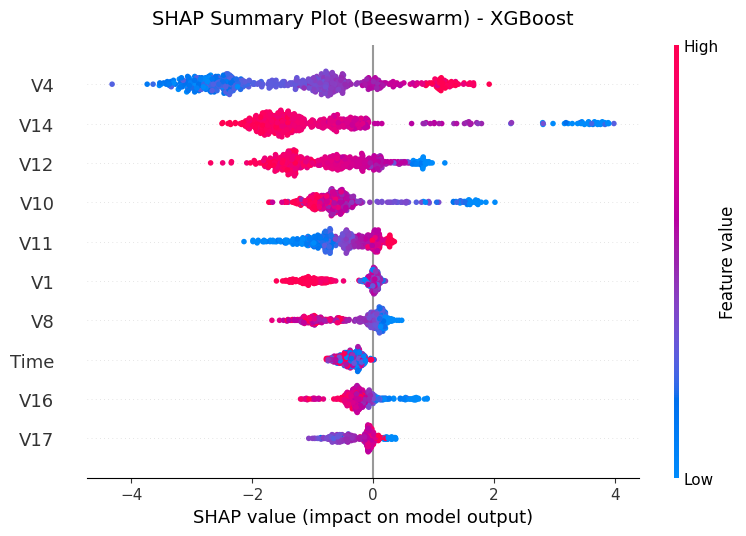

/tmp/ipykernel_909/1918890294.py:40: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


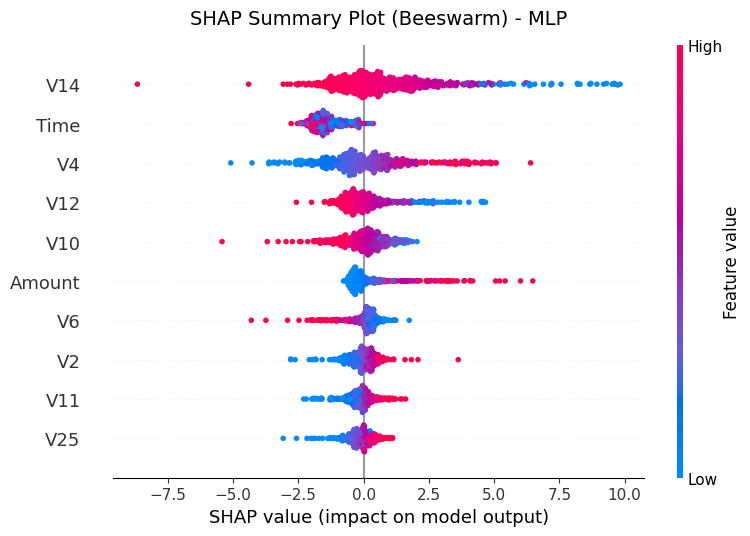

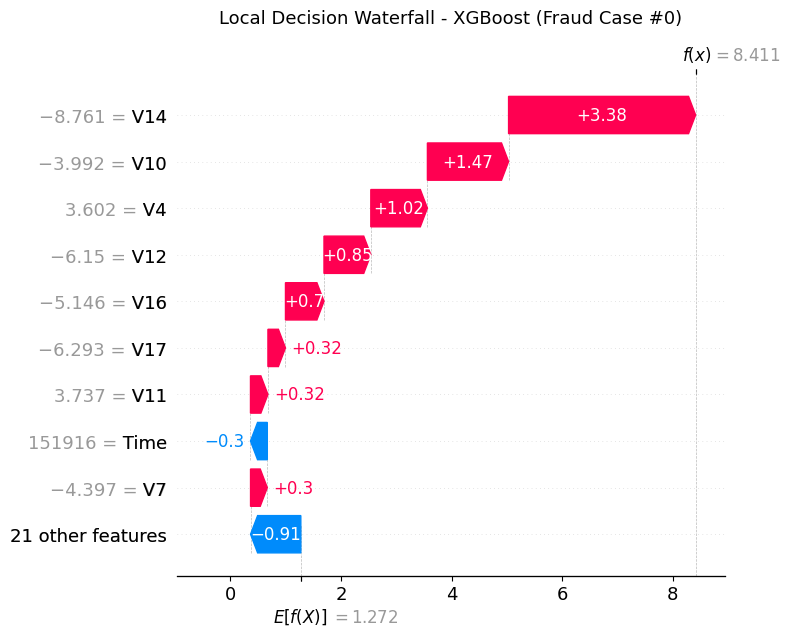

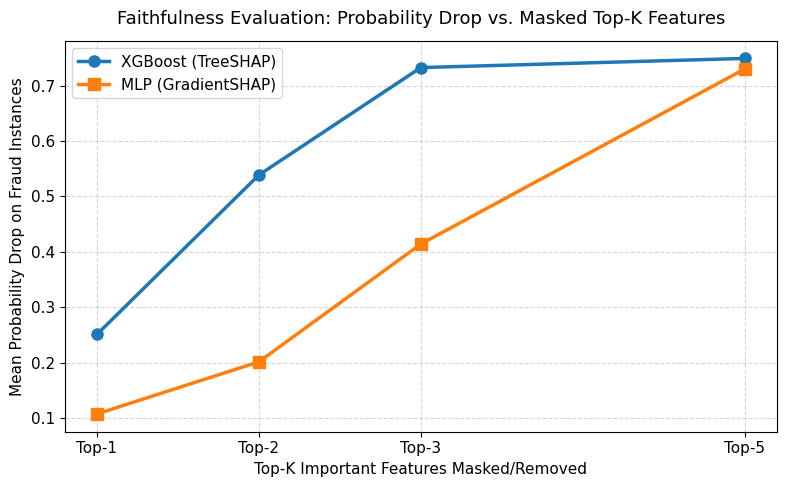

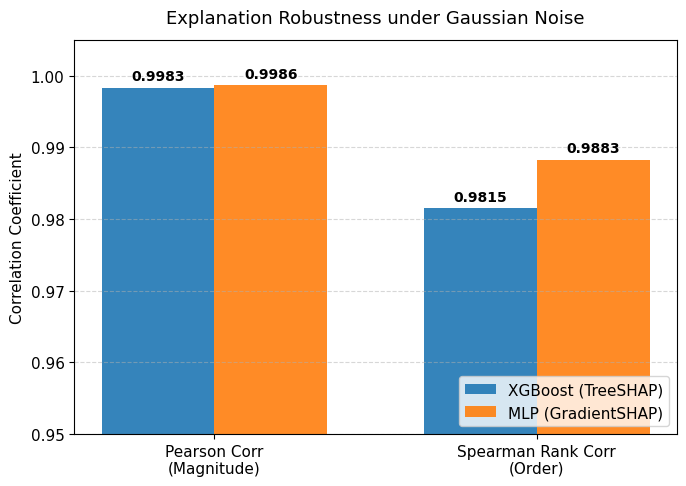


All 5 thesis figures have been saved to './thesis_figures/' folder.


In [22]:
# ==============================================================================
# Step 12: Publication-Ready Visualizations for Thesis (Chapter 4)
# ==============================================================================

import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

# Output directory for thesis figures
os.makedirs("thesis_figures", exist_ok=True)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 11

print("Generating Thesis Visualizations...")

# ------------------------------------------------------------------------------
# 1. SHAP Beeswarm Summary Plot for XGBoost
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values_xgb,
    X_test_eval_xgb,
    feature_names=FEATURE_COLS,
    max_display=10,
    show=False,
)
plt.title("SHAP Summary Plot (Beeswarm) - XGBoost", fontsize=14, pad=15)
plt.tight_layout()
plt.savefig(
    "thesis_figures/fig1_shap_summary_xgb.png", dpi=300, bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------------------------
# 2. SHAP Beeswarm Summary Plot for MLP
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values_mlp,
    X_eval_mlp_arr,
    feature_names=FEATURE_COLS,
    max_display=10,
    show=False,
)
plt.title("SHAP Summary Plot (Beeswarm) - MLP", fontsize=14, pad=15)
plt.tight_layout()
plt.savefig(
    "thesis_figures/fig2_shap_summary_mlp.png", dpi=300, bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------------------------
# 3. Local Explanation: Waterfall Plot for a Real Fraud Case
# ------------------------------------------------------------------------------
# Select the first True Fraud instance in the evaluation set
fraud_indices_local = np.where(y_test_eval.values == 1)[0]
sample_idx = fraud_indices_local[0]

# Expected base value for XGBoost
base_val_xgb = (
    xgb_explainer.expected_value[1]
    if isinstance(xgb_explainer.expected_value, (list, np.ndarray))
    else xgb_explainer.expected_value
)

# Create Explanation object for XGBoost
xgb_sample_exp = shap.Explanation(
    values=shap_values_xgb[sample_idx],
    base_values=base_val_xgb,
    data=X_test_eval_xgb.iloc[sample_idx].values,
    feature_names=FEATURE_COLS,
)

plt.figure(figsize=(10, 6))
shap.plots.waterfall(xgb_sample_exp, max_display=10, show=False)
plt.title(
    f"Local Decision Waterfall - XGBoost (Fraud Case #{sample_idx})",
    fontsize=13,
    pad=15,
)
plt.tight_layout()
plt.savefig(
    "thesis_figures/fig3_shap_waterfall_xgb.png", dpi=300, bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------------------------
# 4. Comparative Faithfulness (Fidelity) Curve
# ------------------------------------------------------------------------------
k_vals = [1, 2, 3, 5]
xgb_drops = [xgb_fidelity[k] for k in k_vals]
mlp_drops = [mlp_fidelity[k] for k in k_vals]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    k_vals,
    xgb_drops,
    marker="o",
    linewidth=2.5,
    markersize=8,
    label="XGBoost (TreeSHAP)",
    color="#1f77b4",
)
ax.plot(
    k_vals,
    mlp_drops,
    marker="s",
    linewidth=2.5,
    markersize=8,
    label="MLP (GradientSHAP)",
    color="#ff7f0e",
)

ax.set_title(
    "Faithfulness Evaluation: Probability Drop vs. Masked Top-K Features",
    fontsize=13,
    pad=12,
)
ax.set_xlabel("Top-K Important Features Masked/Removed", fontsize=11)
ax.set_ylabel("Mean Probability Drop on Fraud Instances", fontsize=11)
ax.set_xticks(k_vals)
ax.set_xticklabels([f"Top-{k}" for k in k_vals])
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(
    "thesis_figures/fig4_faithfulness_curve.png", dpi=300, bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------------------------
# 5. Stability & Robustness Comparison Bar Chart
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 5))
metrics = ["Pearson Corr\n(Magnitude)", "Spearman Rank Corr\n(Order)"]
x = np.arange(len(metrics))
width = 0.35

xgb_stability = [xgb_p_corr, xgb_s_corr]
mlp_stability = [mlp_p_corr, mlp_s_corr]

rects1 = ax.bar(
    x - width / 2,
    xgb_stability,
    width,
    label="XGBoost (TreeSHAP)",
    color="#1f77b4",
    alpha=0.9,
)
rects2 = ax.bar(
    x + width / 2,
    mlp_stability,
    width,
    label="MLP (GradientSHAP)",
    color="#ff7f0e",
    alpha=0.9,
)

ax.set_title("Explanation Robustness under Gaussian Noise", fontsize=13, pad=12)
ax.set_ylabel("Correlation Coefficient", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim([0.95, 1.005])
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(loc="lower right", fontsize=11)

# Annotate values on top of bars
for rect in rects1 + rects2:
    height = rect.get_height()
    ax.annotate(
        f"{height:.4f}",
        xy=(rect.get_x() + rect.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
plt.savefig(
    "thesis_figures/fig5_stability_comparison.png", dpi=300, bbox_inches="tight"
)
plt.show()

print("\nAll 5 thesis figures have been saved to './thesis_figures/' folder.")
